# SHIELD-X Glove: model comparison

This notebook compares the machine learning models for the two tasks of the glove and analyses which one is better.

| Task | Input | Classes |
|---|---|---|
| Gas | MQ-2 and MQ-7 ratios, temperature, humidity | clean, smoke, alcohol, combustible |
| Activity | 3 second windows of the MPU6050 | fall, walk, run, sit, wave, jump |

**Important:** every CSV in `data/` is currently marked `source = simulation`. The scores below show how the pipeline behaves on simulated data. They are **not valid results for the report**. When real glove data (`source = live`) is added to `data/`, run the notebook again and report those numbers.

**How the models are tested.** A single train/test split gives one number per model and hides the fluctuation. Here every model is tested with *leave-one-session-out* cross-validation: each session (one lab visit, or one dashboard export) is held back in turn, the model is trained on the rest, and the scores are collected per fold. The tables show the **mean and standard deviation** over the folds, so the spread between sessions is visible.

In [1]:
import glob, os, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams['figure.dpi'] = 110
DATA = 'data' if os.path.isdir('data') else '../data'
GAS = ['clean', 'smoke', 'alcohol', 'combustible']
ACT = ['fall', 'walk', 'run', 'sit', 'wave', 'jump']
WIN = 6          # 6 packets = 3 seconds at 2 packets per second

## 1. Data

19,331 rows from 3 files


,rows,sessions,source
name,,,
dashboard_export_1.csv,1372,1,simulation
dashboard_export_2.csv,975,1,simulation
simulated_sample.csv,16984,4,simulation


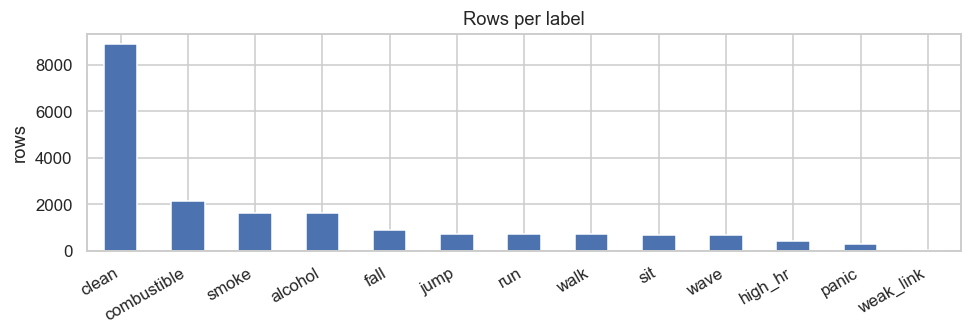

In [2]:
files = sorted(glob.glob(os.path.join(DATA, '*.csv')), key=lambda f: (os.path.basename(f) != 'simulated_sample.csv', f))
INCLUDE_GENERATED = True   # False = use only the CSVs exported from the dashboard (too few sessions for a spread)
if not INCLUDE_GENERATED: files = [f for f in files if os.path.basename(f) != 'simulated_sample.csv']
parts = []
for i, f in enumerate(files):
    d = pd.read_csv(f); d['file'] = i; d['group'] = i * 100 + d['session']; d['name'] = os.path.basename(f); parts.append(d)
df = pd.concat(parts, ignore_index=True)
print(f'{len(df):,} rows from {len(files)} files')
display(df.groupby('name').agg(rows=('label', 'size'), sessions=('session', 'nunique'), source=('source', lambda s: ', '.join(sorted(set(s))))))
fig, ax = plt.subplots(figsize=(9, 3.2))
df['label'].value_counts().plot.bar(ax=ax, color=sns.color_palette()[0]); ax.set_title('Rows per label'); ax.set_ylabel('rows'); ax.set_xlabel('')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

## 2. Features

* **Gas:** the two MQ ratios, the excess of MQ-2 over MQ-7 (separates smoke from alcohol), temperature and humidity. A gas weaker than 0.4 above clean air counts as clean air, the same alert level the dashboard uses (below that no sensor can tell it from clean air).
* **Activity:** mean, standard deviation, minimum and maximum of the acceleration plus the pitch and roll spread, over a 3 second window. A window from a fall run that does not contain the impact is dropped, because lying still is not a fall.

In [3]:
g = df[df['label'].isin(GAS)].copy()
exc = np.maximum(g['mq2_ratio'] - 1, g['mq7_ratio'] - 1)
g.loc[(g['label'] != 'clean') & (exc < 0.4), 'label'] = 'clean'
q = (g['mq2_ratio'] - 1) / np.maximum(g['mq7_ratio'] - 1, 0.05)
Xg = np.column_stack([g['mq2_ratio'], g['mq7_ratio'], q, g['temp_c'], g['humidity_pct']])
yg, grg = g['label'].to_numpy(), g['group'].to_numpy()

def windows(d):
    d = d.copy(); d['label'] = d['label'].replace({'clean': 'sit', 'high_hr': 'sit', 'panic': 'sit', 'weak_link': 'sit'})
    d = d[d['label'].isin(ACT)].reset_index(drop=True)
    X, y, grp = [], [], []
    run_id = ((d['label'] != d['label'].shift()) | (d['group'] != d['group'].shift())).cumsum()
    for _, r in d.groupby(run_id):
        a, p, ro = r['accel_g'].to_numpy(), r['pitch_deg'].to_numpy(), r['roll_deg'].to_numpy()
        for i in range(0, len(r) - WIN + 1, 2):
            s = slice(i, i + WIN)
            if r['label'].iloc[0] == 'fall' and a[s].max() < 2.0: continue
            X.append([a[s].mean(), a[s].std(), a[s].min(), a[s].max(), p[s].std(), ro[s].std()]); y.append(r['label'].iloc[0]); grp.append(r['group'].iloc[0])
    return np.array(X), np.array(y), np.array(grp)

Xa, ya, gra = windows(df)
print('gas rows:', len(yg), '| activity windows:', len(ya))
display(pd.DataFrame({'gas rows': pd.Series(yg).value_counts(), 'activity windows': pd.Series(ya).value_counts()}).fillna(0).astype(int))

gas rows: 14240 | activity windows: 6556


,gas rows,activity windows
alcohol,1096,0
clean,10132,0
combustible,1797,0
fall,0,104
jump,0,352
run,0,345
sit,0,5097
smoke,1215,0
walk,0,338
wave,0,320


## 3. Models

Four learning models and one logistic regression are compared with a **threshold rule** baseline (the fixed rule the dashboard used before any learning). Class weights are balanced so the large clean-air and resting classes do not dominate.

In [4]:
class RuleGas:
    def fit(self, X, y): return self
    def predict(self, X):
        out = []
        for a, b, q_, _, _ in X:
            out.append('clean' if max(a - 1, b - 1) < 0.4 else ('smoke' if q_ > 3 else ('alcohol' if q_ < 0.8 else 'combustible')))
        return np.array(out)
class RuleAct:
    def fit(self, X, y): return self
    def predict(self, X):
        return np.array(['fall' if r[3] > 2.5 else ('run' if r[1] > 0.4 else ('walk' if r[1] > 0.15 else 'sit')) for r in X])

def make_models(task):
    return {
        'Threshold rule': RuleGas() if task == 'gas' else RuleAct(),
        'Decision tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=0),
        'Random forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=0),
        'SVM (RBF)': make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced')),
        'kNN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
        'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    }

## 4. Leave-one-session-out evaluation

For every held-out session the notebook records accuracy, macro precision, macro recall, macro F1 (the average over classes, so small classes count as much as large ones), weighted F1, macro ROC-AUC where the model gives probabilities, and the prediction time.

In [5]:
def run_cv(task, X, y, groups, min_rows=40):
    folds, pooled = [], {}
    classes = GAS if task == 'gas' else ACT
    for grp in np.unique(groups):
        te = groups == grp
        if te.sum() < min_rows or len(np.unique(y[~te])) < 2: continue
        for name, model in make_models(task).items():
            model.fit(X[~te], y[~te])
            t = time.perf_counter(); pred = model.predict(X[te]); ms = (time.perf_counter() - t) / te.sum() * 1000
            p, r, f, _ = precision_recall_fscore_support(y[te], pred, average='macro', zero_division=0)
            fw = precision_recall_fscore_support(y[te], pred, average='weighted', zero_division=0)[2]
            auc = np.nan
            if hasattr(model, 'predict_proba'):
                try:
                    proba = model.predict_proba(X[te]); cl = list(model.classes_); present = [c for c in cl if (y[te] == c).any()]
                    if len(present) >= 2:
                        yb = label_binarize(y[te], classes=cl)[:, [cl.index(c) for c in present]]
                        auc = roc_auc_score(yb, proba[:, [cl.index(c) for c in present]], average='macro')
                except Exception: pass
            folds.append({'task': task, 'model': name, 'held out group': int(grp), 'rows': int(te.sum()), 'accuracy': accuracy_score(y[te], pred),
                          'precision': p, 'recall': r, 'f1': f, 'f1 weighted': fw, 'roc auc': auc, 'ms per row': ms})
            pooled.setdefault(name, ([], []))[0].extend(y[te]); pooled[name][1].extend(pred)
    return pd.DataFrame(folds), pooled

t0 = time.perf_counter()
gas_folds, gas_pooled = run_cv('gas', Xg, yg, grg)
act_folds, act_pooled = run_cv('activity', Xa, ya, gra)
print(f'done in {time.perf_counter() - t0:.0f} s | gas folds: {gas_folds["held out group"].nunique()} | activity folds: {act_folds["held out group"].nunique()}')

done in 20 s | gas folds: 6 | activity folds: 6


In [6]:
METRICS = ['accuracy', 'precision', 'recall', 'f1']
def summary(folds):
    m = folds.groupby('model')[METRICS + ['f1 weighted', 'roc auc', 'ms per row']].mean()
    s = folds.groupby('model')[METRICS].std().add_suffix(' std')
    return m.join(s).sort_values('f1', ascending=False)
gas_sum, act_sum = summary(gas_folds), summary(act_folds)
def show(s):
    t = pd.DataFrame({k: s[k].map('{:.3f}'.format) + ' ± ' + s[k + ' std'].map('{:.3f}'.format) for k in METRICS})
    t['roc auc'] = s['roc auc'].map(lambda v: '-' if np.isnan(v) else f'{v:.3f}'); t['ms per row'] = s['ms per row'].map('{:.4f}'.format)
    return t
print('GAS: mean ± standard deviation over held-out sessions'); display(show(gas_sum))
print('ACTIVITY: mean ± standard deviation over held-out sessions'); display(show(act_sum))

GAS: mean ± standard deviation over held-out sessions


,accuracy,precision,recall,f1,roc auc,ms per row
model,,,,,,
Threshold rule,0.860 ± 0.088,0.747 ± 0.153,0.824 ± 0.099,0.766 ± 0.134,-,0.0010
Decision tree,0.839 ± 0.100,0.705 ± 0.173,0.778 ± 0.147,0.725 ± 0.169,0.921,0.0002
Random forest,0.845 ± 0.074,0.718 ± 0.155,0.717 ± 0.159,0.712 ± 0.152,0.945,0.0062
Logistic regression,0.802 ± 0.090,0.695 ± 0.135,0.776 ± 0.097,0.703 ± 0.125,0.948,0.0004
kNN (k=5),0.805 ± 0.111,0.656 ± 0.208,0.640 ± 0.216,0.638 ± 0.214,0.819,0.0102
SVM (RBF),0.761 ± 0.182,0.647 ± 0.174,0.657 ± 0.238,0.622 ± 0.225,-,0.1624


ACTIVITY: mean ± standard deviation over held-out sessions


,accuracy,precision,recall,f1,roc auc,ms per row
model,,,,,,
SVM (RBF),0.931 ± 0.099,0.814 ± 0.165,0.858 ± 0.109,0.818 ± 0.158,-,0.0374
Logistic regression,0.923 ± 0.096,0.811 ± 0.122,0.823 ± 0.085,0.807 ± 0.113,0.977,0.0008
Random forest,0.928 ± 0.109,0.827 ± 0.190,0.797 ± 0.202,0.796 ± 0.211,0.985,0.0123
kNN (k=5),0.925 ± 0.108,0.805 ± 0.210,0.773 ± 0.225,0.782 ± 0.225,0.974,0.0072
Decision tree,0.917 ± 0.105,0.783 ± 0.198,0.784 ± 0.202,0.778 ± 0.203,0.972,0.0004
Threshold rule,0.861 ± 0.077,0.555 ± 0.229,0.628 ± 0.130,0.563 ± 0.187,-,0.0004


## 5. Graphs

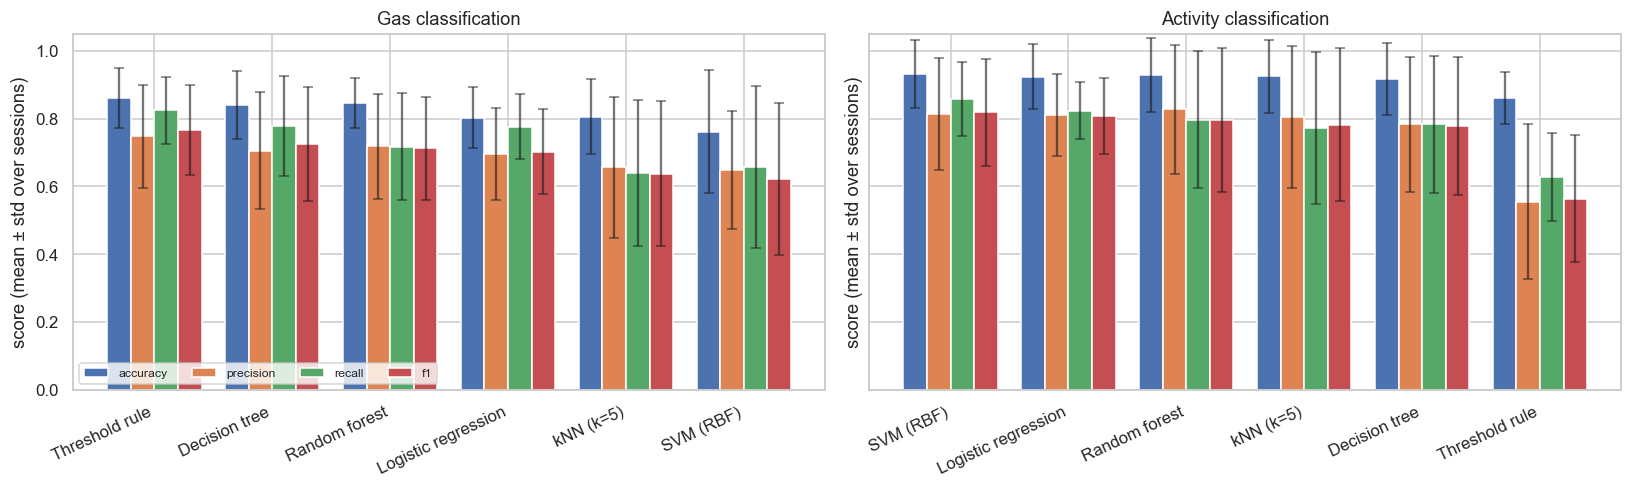

In [7]:
def metric_bars(summ, title, ax):
    models = list(summ.index); x = np.arange(len(models)); w = 0.2
    for i, m in enumerate(METRICS):
        ax.bar(x + (i - 1.5) * w, summ[m], w, yerr=summ[m + ' std'], capsize=3, label=m, error_kw={'alpha': .6})
    ax.set_xticks(x); ax.set_xticklabels(models, rotation=25, ha='right'); ax.set_ylim(0, 1.05); ax.set_title(title); ax.set_ylabel('score (mean ± std over sessions)')
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
metric_bars(gas_sum, 'Gas classification', axes[0]); metric_bars(act_sum, 'Activity classification', axes[1])
axes[0].legend(loc='lower left', ncol=4, fontsize=8); plt.tight_layout(); plt.show()

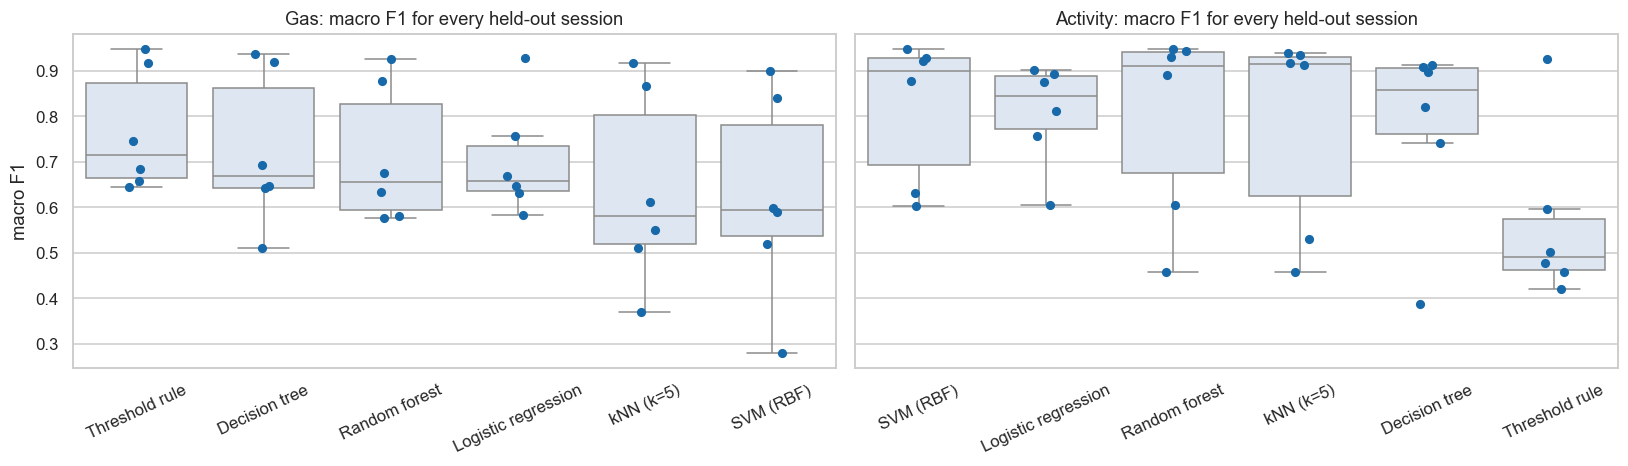

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
for ax, folds, title in zip(axes, (gas_folds, act_folds), ('Gas', 'Activity')):
    order = folds.groupby('model')['f1'].mean().sort_values(ascending=False).index
    sns.boxplot(data=folds, x='model', y='f1', order=order, ax=ax, color='#dbe7f4', fliersize=0)
    sns.stripplot(data=folds, x='model', y='f1', order=order, ax=ax, color='#1769aa', size=6)
    ax.set_title(f'{title}: macro F1 for every held-out session'); ax.set_xlabel(''); ax.set_ylabel('macro F1'); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

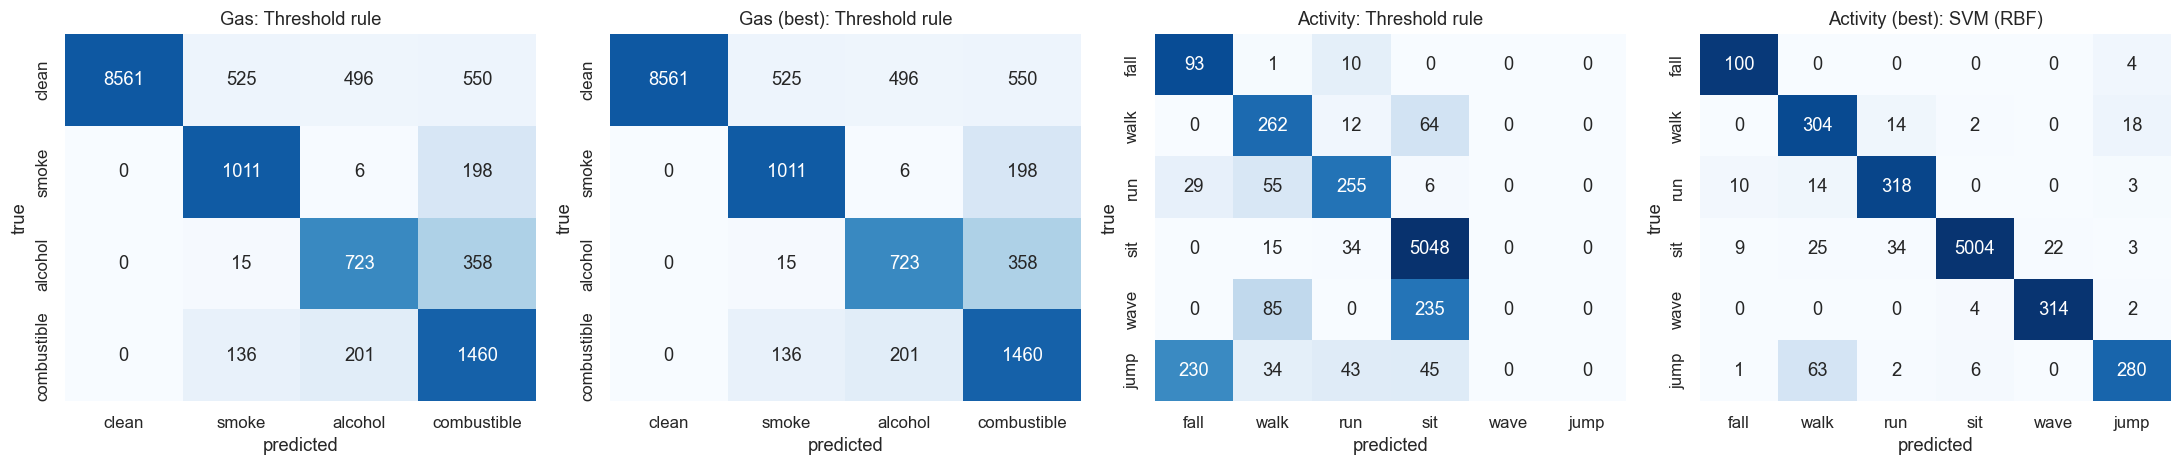

In [9]:
def conf(ax, pooled, name, classes, title):
    yt, yp = pooled[name]; cl = [c for c in classes if c in set(yt) | set(yp)]
    cm = confusion_matrix(yt, yp, labels=cl); cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    sns.heatmap(cmn, annot=cm, fmt='d', cmap='Blues', xticklabels=cl, yticklabels=cl, cbar=False, ax=ax, vmin=0, vmax=1)
    ax.set_title(f'{title}: {name}'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
best_gas, best_act = gas_sum.index[0], act_sum.index[0]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
conf(axes[0], gas_pooled, 'Threshold rule', GAS, 'Gas'); conf(axes[1], gas_pooled, best_gas, GAS, 'Gas (best)')
conf(axes[2], act_pooled, 'Threshold rule', ACT, 'Activity'); conf(axes[3], act_pooled, best_act, ACT, 'Activity (best)')
plt.tight_layout(); plt.show()

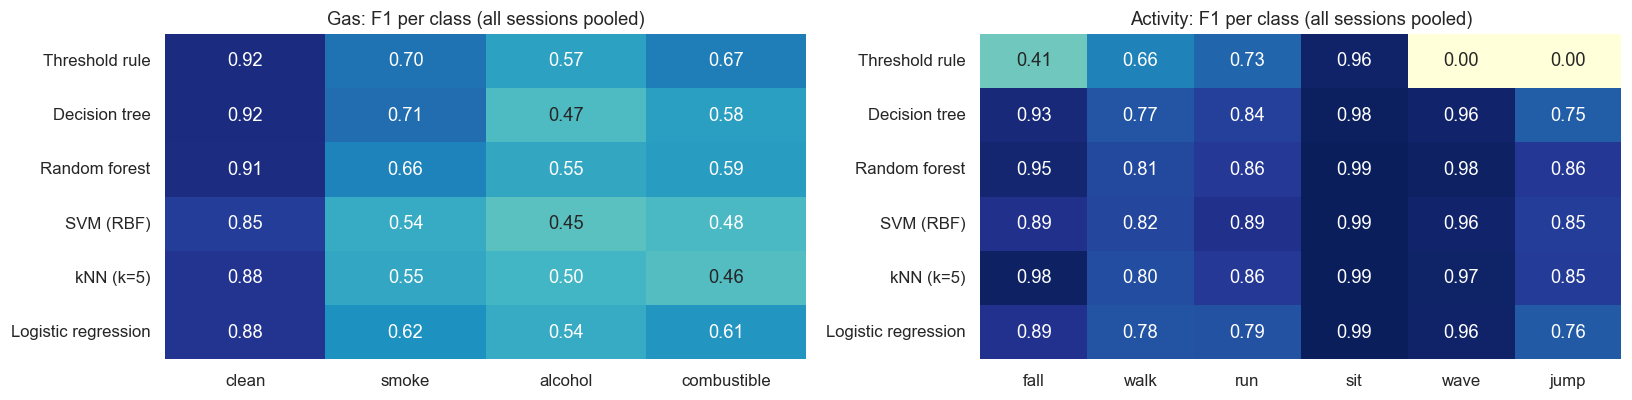

In [10]:
def per_class(pooled, classes):
    rows = {}
    for name, (yt, yp) in pooled.items():
        cl = [c for c in classes if c in set(yt)]
        rows[name] = pd.Series(precision_recall_fscore_support(yt, yp, labels=cl, average=None, zero_division=0)[2], index=cl)
    return pd.DataFrame(rows).T
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
sns.heatmap(per_class(gas_pooled, GAS), annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[0], cbar=False); axes[0].set_title('Gas: F1 per class (all sessions pooled)')
sns.heatmap(per_class(act_pooled, ACT), annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[1], cbar=False); axes[1].set_title('Activity: F1 per class (all sessions pooled)')
plt.tight_layout(); plt.show()

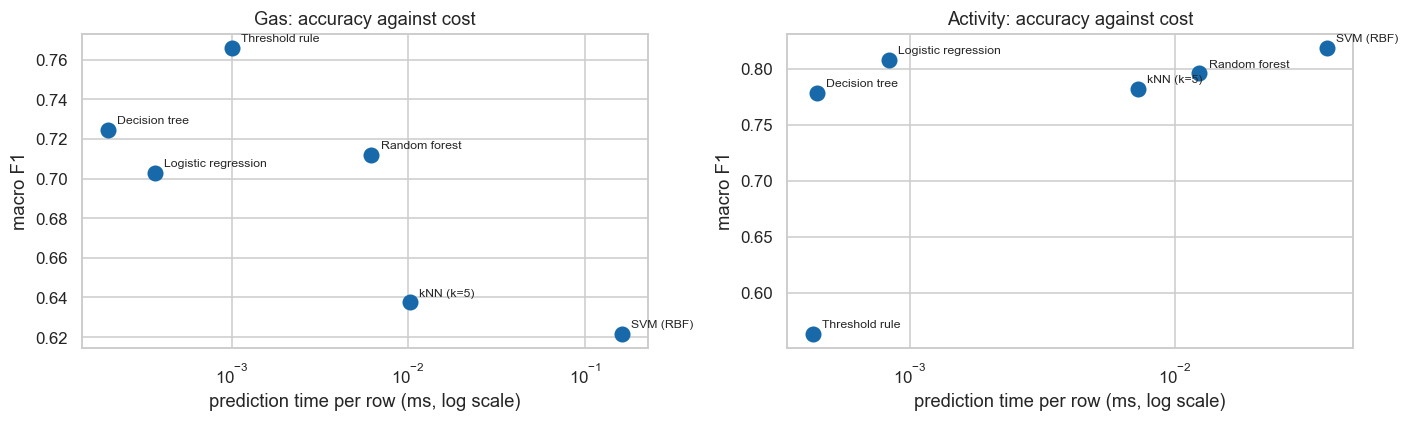

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s, title in zip(axes, (gas_sum, act_sum), ('Gas', 'Activity')):
    ax.scatter(s['ms per row'], s['f1'], s=90, color='#1769aa')
    for n_, r in s.iterrows(): ax.annotate(n_, (r['ms per row'], r['f1']), textcoords='offset points', xytext=(6, 4), fontsize=8)
    ax.set_xscale('log'); ax.set_xlabel('prediction time per row (ms, log scale)'); ax.set_ylabel('macro F1'); ax.set_title(f'{title}: accuracy against cost')
plt.tight_layout(); plt.show()

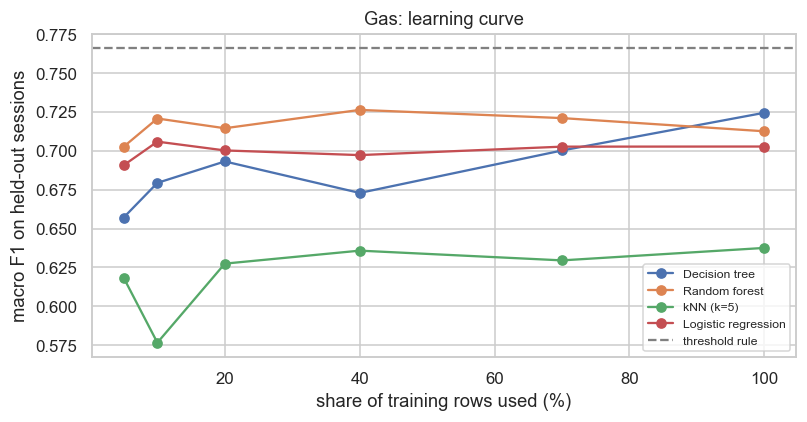

In [12]:
# Learning curve: how many training rows does each gas model need? (held-out sessions, mean F1)
rng = np.random.default_rng(0); fracs = [0.05, 0.1, 0.2, 0.4, 0.7, 1.0]; curves = {}
for name in ['Decision tree', 'Random forest', 'kNN (k=5)', 'Logistic regression']:
    ys = []
    for frac in fracs:
        sc = []
        for grp in np.unique(grg):
            te = grg == grp
            if te.sum() < 40: continue
            tr = np.where(~te)[0]; tr = rng.choice(tr, max(30, int(len(tr) * frac)), replace=False)
            if len(np.unique(yg[tr])) < 2: continue
            m = make_models('gas')[name].fit(Xg[tr], yg[tr]); sc.append(precision_recall_fscore_support(yg[te], m.predict(Xg[te]), average='macro', zero_division=0)[2])
        ys.append(np.mean(sc))
    curves[name] = ys
rule_f1 = gas_sum.loc['Threshold rule', 'f1']
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, ys in curves.items(): ax.plot([f * 100 for f in fracs], ys, marker='o', label=name)
ax.axhline(rule_f1, color='gray', ls='--', label='threshold rule'); ax.set_xlabel('share of training rows used (%)'); ax.set_ylabel('macro F1 on held-out sessions'); ax.set_title('Gas: learning curve'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Ranking and paired comparison with the threshold rule

In [13]:
def rank(folds, task):
    s = folds.groupby('model')['f1'].agg(['mean', 'std']).sort_values('mean', ascending=False); best = s.iloc[0]
    s['within 1 std of best'] = s['mean'] >= best['mean'] - best['std']
    base = folds[folds.model == 'Threshold rule'].set_index('held out group')['f1']
    s['sessions beating the rule'] = [int((folds[folds.model == m].set_index('held out group')['f1'] > base).sum()) if m != 'Threshold rule' else None for m in s.index]
    print(f'{task}: {folds["held out group"].nunique()} held-out sessions'); display(s.round(3))
rank(gas_folds, 'GAS'); rank(act_folds, 'ACTIVITY')

GAS: 6 held-out sessions


,mean,std,within 1 std of best,sessions beating the rule
model,,,,
Threshold rule,0.766,0.134,True,NaN
Decision tree,0.725,0.169,True,2.0
Random forest,0.712,0.152,True,1.0
Logistic regression,0.703,0.125,True,2.0
kNN (k=5),0.638,0.214,True,1.0
SVM (RBF),0.622,0.225,False,0.0


ACTIVITY: 6 held-out sessions


,mean,std,within 1 std of best,sessions beating the rule
model,,,,
SVM (RBF),0.818,0.158,True,5.0
Logistic regression,0.807,0.113,True,5.0
Random forest,0.796,0.211,True,4.0
kNN (k=5),0.782,0.225,True,4.0
Decision tree,0.778,0.203,True,4.0
Threshold rule,0.563,0.187,False,NaN


## 7. Analysis

*Written from the run above (3 CSV files, 19,331 rows, 6 held-out sessions per task). All rows are simulated, so read this as an analysis of how the methods behave, not as a result about the real glove.*

### What the numbers show

**1. The models no longer tie.** Held-out sessions give a different score for every model, and the spread between sessions is large (standard deviation of macro F1 between 0.11 and 0.23). A single train/test split would have hidden this.

**2. Gas classification: learning did not beat the rule.**

| Model | Macro F1 | Accuracy | Sessions better than the rule |
|---|---|---|---|
| Threshold rule | 0.77 ± 0.13 | 0.86 | n/a |
| Decision tree | 0.73 ± 0.17 | 0.84 | 2 of 6 |
| Random forest | 0.71 ± 0.15 | 0.85 | 1 of 6 |
| Logistic regression | 0.70 ± 0.13 | 0.80 | 2 of 6 |
| kNN (k=5) | 0.64 ± 0.21 | 0.81 | 1 of 6 |
| SVM (RBF) | 0.62 ± 0.23 | 0.76 | 0 of 6 |

The rule, the decision tree, the random forest and logistic regression are all within one standard deviation of each other, so they cannot be separated on this data. Only the SVM is clearly behind (it also has the widest spread and is by far the slowest). Macro F1 sits well below accuracy for every model, so the rarer gas classes are harder than clean air, and the models miss or confuse them more often.

The rule has an advantage here that is not real: the simulator and the rule share the same idea (the ratio of the two sensors tells the gases apart), so the rule is close to a perfect model of the generator. On real sensors the ratios will be messier, and this is where learning can help. The ROC-AUC values (0.92 to 0.95 for the tree, forest and logistic regression) show the models do rank the classes well, so the difficulty is in the class boundaries, not in the features.

**3. Activity classification: learning clearly beats the rule.**

| Model | Macro F1 | Accuracy | Sessions better than the rule |
|---|---|---|---|
| SVM (RBF) | 0.82 ± 0.16 | 0.93 | 5 of 6 |
| Logistic regression | 0.81 ± 0.11 | 0.92 | 5 of 6 |
| Random forest | 0.80 ± 0.21 | 0.93 | 4 of 6 |
| kNN (k=5) | 0.78 ± 0.23 | 0.93 | 4 of 6 |
| Decision tree | 0.78 ± 0.20 | 0.92 | 4 of 6 |
| Threshold rule | 0.56 ± 0.19 | 0.86 | n/a |

Every learned model is about 0.22 to 0.26 macro F1 above the rule, and this gap is larger than the session-to-session spread, so it is the one clear finding. The rule reaches 0.86 accuracy only because most windows are "sit". Its macro precision (0.56) shows it fails on the small classes. Among the learned models the differences (0.78 to 0.82) are inside the noise, so they are effectively tied.

### Which model to use

* **Activity:** logistic regression. It is within noise of the SVM, has the smallest spread between sessions (±0.11), is about 50 times faster to run than the SVM, and a linear model is easy to port to the ESP32. The decision tree is the fallback if the simplest possible code is needed (it is the model currently exported to the dashboard).
* **Gas:** on this data there is no evidence that a learned model is worth the added complexity. Keep the decision tree as the dashboard model (it is small, explainable and tied with the rule), and let the real glove data decide. If the real data makes the rule drop and a learned model hold up, switch.
* **Avoid:** the SVM for gas (worst score, widest spread, slowest) and kNN (needs the whole training set, lower recall, high variance).

### Limits of this analysis

* Everything is simulated. The sessions differ because the generator varies them on purpose, not because real sensors behave differently.
* Two of the six folds are single dashboard exports that contain only some classes (for example only 3 run rows in one of them), so their macro scores are noisy. This is part of the large standard deviations.
* Six folds is a small number. Differences of a few hundredths between models are not meaningful.

### What to do with real data

1. Collect real runs with the DIY gas tests and the movement runs, in at least three sessions and with at least three volunteers.
2. Put the CSVs (`source = live`) in `data/`, set `INCLUDE_GENERATED = False` in section 1, and run the notebook again.
3. Report the tables and graphs from that run, together with the spread between sessions. Say clearly that the earlier numbers came from simulated data.